# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python) 

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [1]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# cargar archivos
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')# tu código aquí
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv') # tu código aquí
marketing = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv') # tu código aquí

In [3]:
# explorar datasets
# tu código aquí
datasets = {
    "Orders": orders,
    "Catalog": catalog,
    "Marketing": marketing
}
for nombre, df in datasets.items():
    print(f"\n===== {nombre} =====")
    df.info()
    print("\nEstadísticas descriptivas:")
    display(df.describe(include="all"))


===== Orders =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB

Estadísticas descriptivas:


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
count,25100,25100,25100,24800,25080,25070,25070,25020,25050.000000,25050.000000,25050.000000,2.510000e+04
unique,25000,7642,181,6,2,3,7,3,NaN,NaN,NaN,NaN
top,order_21779,user_7769,2025-06-25,Colombia,desktop,social,Vacuum-Pro-Black,Hogar,NaN,NaN,NaN,NaN
freq,2,11,176,7520,12759,8428,4199,8385,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.092735,259.305549,4.500798,2.072680e+03
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,296.277003,138.726461,5.223010,9.894995e+04
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2.000000,20.030000,0.000000,-4.926500e+02
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,138.377500,0.000000,1.805075e+02
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,258.715000,0.000000,3.417500e+02
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,380.332500,10.000000,5.185800e+02



===== Catalog =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes

Estadísticas descriptivas:


,nombre_producto,categoria_producto,costo_unitario,proveedor
count,7,7,7.000000,7
unique,7,3,NaN,7
top,Vacuum-Pro-Black,Electrónica,NaN,Greene-Smith
freq,1,3,NaN,1
mean,NaN,NaN,102.252857,NaN
std,NaN,NaN,111.011563,NaN
min,NaN,NaN,10.120000,NaN
25%,NaN,NaN,16.905000,NaN
50%,NaN,NaN,25.210000,NaN
75%,NaN,NaN,182.975000,NaN



===== Marketing =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB

Estadísticas descriptivas:


,fecha,pais,id_campaña,canal,gasto
count,1620,1620,1620,1519,1620.00000
unique,180,3,9,3,NaN
top,2025-03-26,Mexico,paid_search_Mexico,paid_search,NaN
freq,9,540,180,507,NaN
mean,NaN,NaN,NaN,NaN,1772.74292
std,NaN,NaN,NaN,NaN,734.43294
min,NaN,NaN,NaN,NaN,501.11000
25%,NaN,NaN,NaN,NaN,1128.03000
50%,NaN,NaN,NaN,NaN,1782.42500
75%,NaN,NaN,NaN,NaN,2420.68500


- Orders -  contiene 25100 filas y 12 columnas
 *En Fecha_hora_pedido es necesario modificar el Dtype a datetime
 *En cantidad es necesario cambiar a int64 (números enteros)
 * Es necesario indentificar los valores faltantes en las columnas de País (300 valores faltantes), dispositivo (60 valores faltantes), fuente_ referencia y nombre_producto (30 valores faltantes), categoría_producto (80 valores faltantes), cantidad, precio_unitario y monto_descuento (50 valores faltantes).
 * 
Respecto a la estadistica descriptiva.

*En la columna Cantidad hay valores min de -2 es decir monto negativo y como max 20,000 lo que se tiene que revisar si puede provocar un outlier
*En Monto total existe la misma problematica min negativos y max elevados.

- Catalog- contiene 7 filas y 4 columnas

  * No presenta valores faltantes
 
Respecto a la estadistica descriptiva.
*La media es mayor que la mediana por lo que se tiene que revisar los costos. 

 
-Marketing- contiene 1620 filas y 5 columnas
 *En Fecha es necesario modificar el Dtype a datetime.
 *En la columna de CANAL existen (101 valores faltantes)

 Respecto a la estadistica descriptiva.
 *La media y la mediana no presentan valores muy diferentes, por lo que no se observa una asimetría tan marcada.

 
  

 


In [4]:
orders_clean = orders.copy()
catalog_clean = catalog.copy()
marketing_clean = marketing.copy()

datasets = {
    "Orders_clean": orders_clean,
    "Catalog_clean": catalog_clean,
    "Marketing_clean": marketing_clean
}

In [5]:
for nombre, df in datasets.items():
    print(f"\n===== {nombre} =====")
    display(df.head(5))


===== Orders_clean =====


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28



===== Catalog_clean =====


,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"



===== Marketing_clean =====


,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


---

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas 

---

In [6]:
orders_clean["fecha_hora_pedido"] = pd.to_datetime(
    orders_clean["fecha_hora_pedido"],
    errors="coerce"
) # tu código aquí

In [7]:
orders_clean["fecha_hora_pedido"].dtype

dtype('<M8[ns]')

In [8]:
marketing_clean["fecha"] = pd.to_datetime(
    marketing_clean["fecha"],
    errors="coerce"
)

In [9]:
marketing_clean["fecha"].dtype

dtype('<M8[ns]')

--Se procede a realizar el cambio de dtype de las columnas "fecha_hora_pedido" y "fecha" a datetime.--

In [10]:
for nombre, df in datasets.items():
    print(f"\n===== {nombre} =====")

    columnas_numericas = df.select_dtypes(
        include=["int64", "float64"]
    ).columns

    print(columnas_numericas.tolist())
    


===== Orders_clean =====
['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']

===== Catalog_clean =====
['costo_unitario']

===== Marketing_clean =====
['gasto']


In [11]:
for nombre, df in datasets.items():
    print(f"\n===== {nombre} =====")

    columnas_num = df.select_dtypes(
        include="number"
    ).columns

    for columna in columnas_num:
        negativos = (df[columna] < 0).sum()
        ceros = (df[columna] == 0).sum()

        print(f"\nColumna: {columna}")
        print(f"Valores negativos: {negativos}")
        print(f"Valores en cero: {ceros}")


===== Orders_clean =====

Columna: cantidad
Valores negativos: 4
Valores en cero: 0

Columna: precio_unitario
Valores negativos: 0
Valores en cero: 0

Columna: monto_descuento
Valores negativos: 0
Valores en cero: 12551

Columna: monto_total
Valores negativos: 4
Valores en cero: 0

===== Catalog_clean =====

Columna: costo_unitario
Valores negativos: 0
Valores en cero: 0

===== Marketing_clean =====

Columna: gasto
Valores negativos: 0
Valores en cero: 0


In [12]:
for nombre, df in datasets.items():
    print(f"\n===== {nombre} =====")

    nulos = pd.DataFrame({
        "Nulos": df.isna().sum(),
        "Porcentaje (%)": (
            df.isna().mean() * 100
        ).round(2)
    })

    display(nulos)


===== Orders_clean =====


,Nulos,Porcentaje (%)
id_pedido,0,0.00
id_usuario,0,0.00
fecha_hora_pedido,0,0.00
pais,300,1.20
dispositivo,20,0.08
fuente_referencia,30,0.12
nombre_producto,30,0.12
categoria_producto,80,0.32
cantidad,50,0.20
precio_unitario,50,0.20



===== Catalog_clean =====


,Nulos,Porcentaje (%)
nombre_producto,0,0.0
categoria_producto,0,0.0
costo_unitario,0,0.0
proveedor,0,0.0



===== Marketing_clean =====


,Nulos,Porcentaje (%)
fecha,0,0.00
pais,0,0.00
id_campaña,0,0.00
canal,101,6.23
gasto,0,0.00


In [13]:
for nombre, df in datasets.items():
    filas_originales = len(df)
    filas_completas = len(df.dropna())

    filas_eliminadas = filas_originales - filas_completas

    print(f"\n===== {nombre} =====")
    print("Filas originales:", filas_originales)
    print("Filas que se eliminarían:", filas_eliminadas)
    print("Filas restantes:", filas_completas)
    print(
        "Pérdida (%):",
        round(filas_eliminadas / filas_originales * 100, 2)
    )


===== Orders_clean =====
Filas originales: 25100
Filas que se eliminarían: 400
Filas restantes: 24700
Pérdida (%): 1.59

===== Catalog_clean =====
Filas originales: 7
Filas que se eliminarían: 0
Filas restantes: 7
Pérdida (%): 0.0

===== Marketing_clean =====
Filas originales: 1620
Filas que se eliminarían: 101
Filas restantes: 1519
Pérdida (%): 6.23


- orders_clean-
  *Se encuentran valores negativos en 2 columnas, 4 en cantidad y 4 monto total
  *De acuerdo a los valores nulos presentados si se decide eliminar filas, serían 400 que representa 1.59% de los datos

-Markketing_clean- 
  Presenta 101 valores nulos lo que representa 6.23% de los datos. que podrían ser eliminidados. 




In [14]:
orders_clean["monto_esperado"] = (
    orders_clean["cantidad"] *
    orders_clean["precio_unitario"]
    - orders_clean["monto_descuento"]
)

orders_clean["diferencia_monto"] = (
    orders_clean["monto_total"] -
    orders_clean["monto_esperado"]
)

In [15]:
inconsistencias = orders_clean[
    orders_clean["diferencia_monto"].abs() > 0.01
]

print("Registros inconsistentes:", len(inconsistencias))

display(inconsistencias[
    [
        "id_pedido",
        "cantidad",
        "precio_unitario",
        "monto_descuento",
        "monto_total",
        "monto_esperado",
        "diferencia_monto"
    ]
].head(10))

Registros inconsistentes: 1149


,id_pedido,cantidad,precio_unitario,monto_descuento,monto_total,monto_esperado,diferencia_monto
2,order_2,2.0,102.99,10.0,195.99,195.98,0.01
24,order_24,2.0,117.99,0.0,235.99,235.98,0.01
35,order_35,2.0,467.34,5.0,929.69,929.68,0.01
41,order_41,2.0,37.77,10.0,65.53,65.54,-0.01
136,order_136,2.0,211.05,15.0,407.09,407.10,-0.01
180,order_180,2.0,451.16,15.0,887.31,887.32,-0.01
261,order_261,2.0,209.33,10.0,408.65,408.66,-0.01
266,order_266,-2.0,101.31,10.0,-192.62,-212.62,20.00
267,order_267,-1.0,43.50,5.0,-38.50,-48.50,10.00
268,order_268,-1.0,497.65,5.0,-492.65,-502.65,10.00


In [16]:
columnas_validacion = [
    "cantidad",
    "precio_unitario",
    "monto_descuento",
    "monto_total"
]

sin_datos = orders_clean[
    columnas_validacion
].isna().any(axis=1)

diferencia = orders_clean[
    "diferencia_monto"
].abs()

orders_clean["estado_monto"] = np.select(
    [
        sin_datos,
        diferencia <= 0.01,
        diferencia > 0.01
    ],
    [
        "No evaluable",
        "Consistente",
        "Inconsistente"
    ],
    default="Revisar"
)

orders_clean["estado_monto"].value_counts()

Consistente      23901
Inconsistente     1149
No evaluable        50
Name: estado_monto, dtype: int64

In [17]:
display(
    catalog_clean[
        ["nombre_producto", "costo_unitario"]
    ].sort_values("costo_unitario")
)

,nombre_producto,costo_unitario
1,Phone-Pro-128GB,10.12
4,Vacuum-Pro-Black,16.60
5,Sneakers-Urban-42,17.21
2,Tablet-Standard-64GB,25.21
3,Blender-XL-Red,176.64
6,Jacket-Winter-M,189.31
0,Laptop-Gaming-16GB,280.68


En Orders, se estableció una comprobación entre el monto total registrado y el monto esperado, calculado a partir de la cantidad, el precio unitario y el descuento aplicado. Se consideró una tolerancia de 0.01 para posibles diferencias de redondeo.

Los registros se clasificaron en consistentes, inconsistentes y no evaluables, según la disponibilidad de información y el resultado de la validación.

In [18]:
display(
    orders_clean[
        (orders_clean["cantidad"] < 0) |
        (orders_clean["monto_total"] < 0)
    ][
        [
            "id_pedido",
            "cantidad",
            "precio_unitario",
            "monto_descuento",
            "monto_total"
        ]
    ]
)

,id_pedido,cantidad,precio_unitario,monto_descuento,monto_total
266,order_266,-2.0,101.31,10.0,-192.62
267,order_267,-1.0,43.50,5.0,-38.50
268,order_268,-1.0,497.65,5.0,-492.65
269,order_269,-1.0,423.53,0.0,-423.53


In [19]:
orders_clean["tipo_movimiento"] = np.where(
    (orders_clean["cantidad"] < 0) &
    (orders_clean["monto_total"] < 0),
    "Posible devolución",
    "Venta u otro movimiento"
)

Se crea una columna para diferencias las  cantidades negativas como posible devolución.

In [20]:
orders_clean["tipo_movimiento"].value_counts()


Venta u otro movimiento    25096
Posible devolución             4
Name: tipo_movimiento, dtype: int64

In [21]:
devoluciones = orders_clean[
    orders_clean["tipo_movimiento"] == "Posible devolución"
].copy()

devoluciones["monto_esperado"] = (
    devoluciones["cantidad"] *
    devoluciones["precio_unitario"]
    + devoluciones["monto_descuento"]
)

devoluciones["diferencia"] = (
    devoluciones["monto_total"]
    - devoluciones["monto_esperado"]
)

display(devoluciones[
    ["id_pedido", "monto_total",
     "monto_esperado", "diferencia"]
])


,id_pedido,monto_total,monto_esperado,diferencia
266,order_266,-192.62,-192.62,0.0
267,order_267,-38.50,-38.50,0.0
268,order_268,-492.65,-492.65,0.0
269,order_269,-423.53,-423.53,0.0


Durante el análisis de calidad de datos del dataset Orders, se identificaron cuatro registros con cantidades y montos totales negativos.
Al revisar las transacciones, se observó que los importes registrados son consistentes con una fórmula alternativa en la que el descuento se suma al importe negativo de la transacción.
Este comportamiento podría corresponder a devoluciones o reembolsos, aunque se requiere confirmar su significado mediante las reglas del negocio.
Por lo tanto, se decidió conservar provisionalmente estos registros y clasificarlos como posibles devoluciones, evitando eliminarlos sin una justificación.

In [22]:
for nombre, df in datasets.items():
    print(f"\n===== {nombre} =====")
    print("Duplicados exactos:", df.duplicated().sum())


===== Orders_clean =====
Duplicados exactos: 100

===== Catalog_clean =====
Duplicados exactos: 0

===== Marketing_clean =====
Duplicados exactos: 0


In [23]:
for nombre, df in datasets.items():
    print(f"\n===== {nombre} =====")

    duplicados = df[
        df.duplicated(keep=False)
    ]

    display(duplicados.head(10))


===== Orders_clean =====


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,monto_esperado,diferencia_monto,estado_monto,tipo_movimiento
734,order_734,user_6347,2025-05-02,Colombia,desktop,organic,Blender-XL-Red,Hogar,1.0,58.00,0.0,58.00,58.00,0.00,Consistente,Venta u otro movimiento
812,order_812,user_1530,2025-03-31,Argentina,desktop,organic,Tablet-Standard-64GB,Electronica,1.0,167.32,10.0,157.32,157.32,0.00,Consistente,Venta u otro movimiento
974,order_974,user_3262,2025-05-04,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,2.0,268.58,5.0,532.16,532.16,0.00,Consistente,Venta u otro movimiento
1361,order_1361,user_507,2025-06-27,Mexico,desktop,paid_search,Laptop-Gaming-16GB,Electronica,2.0,239.61,0.0,479.22,479.22,0.00,Consistente,Venta u otro movimiento
1735,order_1735,user_728,2025-05-13,Mexico,mobile,social,Tablet-Standard-64GB,Electronica,2.0,419.04,0.0,838.08,838.08,0.00,Consistente,Venta u otro movimiento
2379,order_2379,user_4682,2025-03-31,Mexico,mobile,paid_search,Vacuum-Pro-Black,Hogar,2.0,480.39,10.0,950.78,950.78,0.00,Consistente,Venta u otro movimiento
2470,order_2470,user_2056,2025-02-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,471.43,0.0,942.85,942.86,-0.01,Consistente,Venta u otro movimiento
2555,order_2555,user_5161,2025-03-16,Colombia,mobile,paid_search,Laptop-Gaming-16GB,Electronica,2.0,100.26,0.0,200.53,200.52,0.01,Consistente,Venta u otro movimiento
2583,order_2583,user_7796,2025-01-01,Colombia,mobile,organic,Laptop-Gaming-16GB,Electronica,2.0,167.61,10.0,325.22,325.22,0.00,Consistente,Venta u otro movimiento
2825,order_2825,user_3761,2025-01-02,Colombia,desktop,organic,Phone-Pro-128GB,Electronica,1.0,212.65,0.0,212.65,212.65,0.00,Consistente,Venta u otro movimiento



===== Catalog_clean =====


,nombre_producto,categoria_producto,costo_unitario,proveedor



===== Marketing_clean =====


,fecha,pais,id_campaña,canal,gasto


In [24]:
orders_clean = orders_clean.drop_duplicates().copy()

In [25]:
print("Registros restantes:", len(orders_clean))

print(
    "Duplicados restantes:",
    orders_clean.duplicated().sum()
)

print(
    "IDs de pedido únicos:",
    orders_clean["id_pedido"].nunique()
)

Registros restantes: 25000
Duplicados restantes: 0
IDs de pedido únicos: 25000


Durante la revisión de calidad de datos, se identificaron 100 registros duplicados exactos en el dataset Orders, equivalentes al 0.40% de sus 25,100 registros originales.
Tras confirmar que las filas repetidas no representaban transacciones independientes, se aplicó el método drop_duplicates() para conservar un único registro por cada fila idéntica, obteniendo 25,000 registros.
En los datasets Catalog y Marketing no se identificaron duplicados exactos, por lo que se conservaron sus 7 y 1,620 registros, respectivamente.
Esta limpieza permite reducir el riesgo de sobreestimar los ingresos, las cantidades vendidas y otros indicadores comerciales.

In [26]:
datasets = {
    "Orders_clean": orders_clean,
    "Catalog_clean": catalog_clean,
    "Marketing_clean": marketing_clean
}

for nombre, df in datasets.items():
    print(f"\n===== {nombre} =====")

    columnas_cat = df.select_dtypes(
        include=["object", "string", "category"]
    ).columns

    print(columnas_cat.tolist())


===== Orders_clean =====
['id_pedido', 'id_usuario', 'pais', 'dispositivo', 'fuente_referencia', 'nombre_producto', 'categoria_producto', 'estado_monto', 'tipo_movimiento']

===== Catalog_clean =====
['nombre_producto', 'categoria_producto', 'proveedor']

===== Marketing_clean =====
['pais', 'id_campaña', 'canal']


In [27]:
columnas_categoricas = {
    "Orders_clean": [
        "pais",
        "dispositivo",
        "fuente_referencia",
        "nombre_producto",
        "categoria_producto"
    ],
    "Catalog_clean": [
        "nombre_producto",
        "categoria_producto",
        "proveedor"
    ],
    "Marketing_clean": [
        "pais",
        "id_campaña",
        "canal"
    ]
}

for nombre, columnas in columnas_categoricas.items():
    df = datasets[nombre]

    print(f"\n===== {nombre} =====")

    for columna in columnas:
        print(f"\n{columna}:")
        print(df[columna].value_counts(dropna=False))


===== Orders_clean =====

pais:
Colombia     7481
Mexico       7478
Argentina    7259
mexico        863
colombia      823
argentina     796
NaN           300
Name: pais, dtype: int64

dispositivo:
desktop    12711
mobile     12269
NaN           20
Name: dispositivo, dtype: int64

fuente_referencia:
social         8402
organic        8288
paid_search    8280
NaN              30
Name: fuente_referencia, dtype: int64

nombre_producto:
Blender-XL-Red          4179
Vacuum-Pro-Black        4176
Jacket-Winter-M         4176
Sneakers-Urban-42       4148
Laptop-Gaming-16GB      2782
Tablet-Standard-64GB    2769
Phone-Pro-128GB         2740
NaN                       30
Name: nombre_producto, dtype: int64

categoria_producto:
Hogar          8346
Moda           8295
Electronica    8279
NaN              80
Name: categoria_producto, dtype: int64

===== Catalog_clean =====

nombre_producto:
Vacuum-Pro-Black        1
Tablet-Standard-64GB    1
Phone-Pro-128GB         1
Jacket-Winter-M         1
Sneake

In [28]:
orders_clean["pais"] = (
    orders_clean["pais"]
    .replace({
        "colombia": "Colombia",
        "mexico": "Mexico",
        "argentina": "Argentina"
    })
)

In [29]:
orders_clean["pais"].value_counts(dropna=False)

Mexico       8341
Colombia     8304
Argentina    8055
NaN           300
Name: pais, dtype: int64

In [30]:
orders_clean["categoria_producto"] = (
    orders_clean["categoria_producto"]
    .replace({
        "Electronica": "Electrónica"
    })
)

In [31]:
orders_clean["categoria_producto"].value_counts(
    dropna=False
)

Hogar          8346
Moda           8295
Electrónica    8279
NaN              80
Name: categoria_producto, dtype: int64

In [32]:
orders_clean = orders_clean.merge(
    catalog_clean[
        ["nombre_producto", "categoria_producto"]
    ],
    on="nombre_producto",
    how="left",
    suffixes=("", "_catalog"),
    validate="many_to_one"
)

orders_clean["categoria_producto"] = (
    orders_clean["categoria_producto"].fillna(
        orders_clean["categoria_producto_catalog"]
    )
)

orders_clean.drop(
    columns=["categoria_producto_catalog"],
    inplace=True
)

In [33]:
orders_clean["categoria_producto"].isna().sum()

30

In [34]:
marketing_clean.groupby("id_campaña")[
    "canal"
].nunique()

id_campaña
organic_Argentina        1
organic_Colombia         1
organic_Mexico           1
paid_search_Argentina    1
paid_search_Colombia     1
paid_search_Mexico       1
social_Argentina         1
social_Colombia          1
social_Mexico            1
Name: canal, dtype: int64

In [35]:
marketing_clean.groupby("id_campaña")["canal"].unique()

id_campaña
organic_Argentina            [organic, nan]
organic_Colombia             [organic, nan]
organic_Mexico               [organic, nan]
paid_search_Argentina    [paid_search, nan]
paid_search_Colombia     [paid_search, nan]
paid_search_Mexico       [paid_search, nan]
social_Argentina              [social, nan]
social_Colombia               [social, nan]
social_Mexico                 [social, nan]
Name: canal, dtype: object

In [36]:
# Crear la relación entre campaña y canal
mapa_canales = (
    marketing_clean
    .dropna(subset=["canal"])
    .groupby("id_campaña")["canal"]
    .first()
)

# Rellenar los valores nulos
marketing_clean["canal"] = (
    marketing_clean["canal"].fillna(
        marketing_clean["id_campaña"].map(mapa_canales)
    ))

In [37]:
print("Valores nulos restantes:")
print(marketing_clean["canal"].isna().sum())

print("\nDistribución por canal:")
print(marketing_clean["canal"].value_counts())

print("\nTotal de registros:")
print(len(marketing_clean))

Valores nulos restantes:
0

Distribución por canal:
paid_search    540
social         540
organic        540
Name: canal, dtype: int64

Total de registros:
1620


Durante la revisión de variables categóricas del dataset Marketing, se identificaron 101 valores nulos en la columna canal, equivalentes al 6.23% de los registros. Se verificó que cada una de las nueve campañas publicitarias tiene un único canal válido asociado, lo que permitió establecer una correspondencia entre id_campaña y canal.
A partir de esta relación, se recuperaron los valores faltantes mediante una imputación basada en información existente, conservando los 1,620 registros originales y evitando la pérdida de datos relacionados con el gasto publicitario.

In [38]:
orders_clean["categoria_producto"] = (
    orders_clean["categoria_producto"]
    .fillna("No identificado")
)

In [39]:
print(
    orders_clean["categoria_producto"]
    .value_counts(dropna=False)
)

Hogar              8355
Moda               8324
Electrónica        8291
No identificado      30
Name: categoria_producto, dtype: int64


Durante la limpieza del dataset Orders se identificaron 80 valores nulos en la variable categoria_producto.
Mediante la integración de información del catálogo de productos, se recuperaron 50 categorías, equivalentes al 62.5% de los valores faltantes originales.
Los 30 registros restantes (37.5%) se clasificaron como "No identificado", debido a la ausencia de información suficiente para determinar su categoría.
Adicionalmente, se estandarizó la categoría "Electrónica" para mantener la consistencia entre ambos datasets.
Como resultado, se conservaron los 25,000 registros y se eliminaron los valores nulos de la variable categoria_producto, sin asignar categorías arbitrarias.

In [40]:
pedidos_sin_pais = orders_clean[
    orders_clean["pais"].isna()
]

print("Pedidos sin país:", len(pedidos_sin_pais))

display(
    pedidos_sin_pais[
        ["id_pedido", "id_usuario", "pais", "fuente_referencia"]
    ].head(10)
)

Pedidos sin país: 300


,id_pedido,id_usuario,pais,fuente_referencia
124,order_124,user_6671,NaN,organic
125,order_125,user_5263,NaN,organic
126,order_126,user_4952,NaN,paid_search
127,order_127,user_2619,NaN,paid_search
128,order_128,user_2444,NaN,social
129,order_129,user_7157,NaN,paid_search
130,order_130,user_3279,NaN,paid_search
131,order_131,user_2914,NaN,organic
132,order_132,user_2173,NaN,organic
133,order_133,user_4038,NaN,social


In [41]:
paises_por_usuario = (
    orders_clean
    .dropna(subset=["pais"])
    .groupby("id_usuario")["pais"]
    .nunique()
)

print(
    "Usuarios con más de un país:",
    (paises_por_usuario > 1).sum()
)

Usuarios con más de un país: 0


In [42]:
orders_clean["pais"] = (
    orders_clean["pais"].fillna("No identificado")
)

In [43]:
print(orders_clean["pais"].value_counts(dropna=False))

print("\nValores nulos restantes:")
print(orders_clean["pais"].isna().sum())

Mexico             8341
Colombia           8304
Argentina          8055
No identificado     300
Name: pais, dtype: int64

Valores nulos restantes:
0


Se identificaron 300 valores nulos en la variable pais, equivalentes al 1.2% de los 25,000 registros del dataset Orders.

Por lo tanto, los 300 valores faltantes se clasificaron como "No identificado", conservando la totalidad de los registros y evitando introducir información geográfica no verificada.

In [44]:
columnas = [
    "dispositivo",
    "fuente_referencia",
    "nombre_producto"
]

print(orders_clean[columnas].isna().sum())

dispositivo          20
fuente_referencia    30
nombre_producto      30
dtype: int64


In [45]:
orders_clean[columnas] = (
    orders_clean[columnas].fillna("No identificado")
)

In [46]:
for columna in columnas:
    print(f"\n===== {columna} =====")
    print(orders_clean[columna].value_counts(dropna=False))


===== dispositivo =====
desktop            12711
mobile             12269
No identificado       20
Name: dispositivo, dtype: int64

===== fuente_referencia =====
social             8402
organic            8288
paid_search        8280
No identificado      30
Name: fuente_referencia, dtype: int64

===== nombre_producto =====
Blender-XL-Red          4179
Vacuum-Pro-Black        4176
Jacket-Winter-M         4176
Sneakers-Urban-42       4148
Laptop-Gaming-16GB      2782
Tablet-Standard-64GB    2769
Phone-Pro-128GB         2740
No identificado           30
Name: nombre_producto, dtype: int64


In [47]:
columnas_categoricas = [
    "pais",
    "dispositivo",
    "fuente_referencia",
    "nombre_producto",
    "categoria_producto"
]

print(
    orders_clean[columnas_categoricas]
    .isna()
    .sum()
)

pais                  0
dispositivo           0
fuente_referencia     0
nombre_producto       0
categoria_producto    0
dtype: int64


Durante la limpieza del dataset Orders se identificaron valores faltantes en las variables dispositivo, fuente_referencia y nombre_producto.
Se decidió conservar los registros y reemplazar los valores nulos por la categoría "No identificado", debido a que no se cuenta con información suficiente para recuperar sus valores originales de manera confiable.
Este tratamiento permite mantener la integridad del conjunto de datos, evitar la pérdida de transacciones y distinguir los registros cuya información categórica no está disponible.
Asimismo, facilita el análisis posterior de ventas por dispositivo, fuente de referencia y producto, sin asignar categorías arbitrarias.

In [48]:
columnas_numericas = [
    "cantidad",
    "precio_unitario",
    "monto_descuento",
    "monto_total"
]

print(orders_clean[columnas_numericas].isna().sum())

cantidad           50
precio_unitario    50
monto_descuento    50
monto_total         0
dtype: int64


In [49]:
columnas_numericas = [
    "cantidad",
    "precio_unitario",
    "monto_descuento"
]

pedidos_nulos = orders_clean[
    orders_clean[columnas_numericas].isna().any(axis=1)
]

print("Pedidos afectados:", len(pedidos_nulos))

display(
    pedidos_nulos[
        [
            "id_pedido",
            "nombre_producto",
            "cantidad",
            "precio_unitario",
            "monto_descuento",
            "monto_total"
        ]
    ].head(15)
)

Pedidos afectados: 50


,id_pedido,nombre_producto,cantidad,precio_unitario,monto_descuento,monto_total
74,order_74,Sneakers-Urban-42,NaN,NaN,NaN,595.85
75,order_75,Sneakers-Urban-42,NaN,NaN,NaN,458.15
76,order_76,Laptop-Gaming-16GB,NaN,NaN,NaN,319.75
77,order_77,Vacuum-Pro-Black,NaN,NaN,NaN,227.55
78,order_78,Phone-Pro-128GB,NaN,NaN,NaN,432.39
79,order_79,Sneakers-Urban-42,NaN,NaN,NaN,527.15
80,order_80,Vacuum-Pro-Black,NaN,NaN,NaN,711.18
81,order_81,Tablet-Standard-64GB,NaN,NaN,NaN,41.08
82,order_82,Sneakers-Urban-42,NaN,NaN,NaN,431.55
83,order_83,Sneakers-Urban-42,NaN,NaN,NaN,279.35


In [50]:
orders_clean["estado_datos"] = np.where(
    orders_clean[
        ["cantidad", "precio_unitario", "monto_descuento"]
    ].isna().any(axis=1),
    "Incompleto",
    "Completo"
)

In [51]:
print(orders_clean["estado_datos"].value_counts())

Completo      24950
Incompleto       50
Name: estado_datos, dtype: int64


Durante la revisión del dataset Orders se identificaron 50 registros con valores faltantes simultáneos en las variables cantidad, precio_unitario y monto_descuento, equivalentes al 0.20% de los 25,000 pedidos.
Se observó que los 50 registros conservan información en la variable monto_total. Sin embargo, no es posible reconstruir de manera confiable los tres campos faltantes utilizando únicamente el importe registrado.
Por lo tanto, se decidió conservar los registros y mantener los valores nulos, evitando imputaciones arbitrarias que pudieran alterar los indicadores comerciales.
Adicionalmente, se propone clasificar los registros como completos o incompletos para facilitar su identificación y excluirlos únicamente de los análisis que requieran las variables faltantes.
Esta estrategia permite preservar la información disponible de ingresos y mantener la transparencia sobre las limitaciones del conjunto de datos.

In [52]:
datasets = {
    "Orders_clean": orders_clean,
    "Catalog_clean": catalog_clean,
    "Marketing_clean": marketing_clean
}

resumen_final = []

for nombre, df in datasets.items():
    resumen_final.append({
        "Dataset": nombre,
        "Registros": len(df),
        "Columnas": df.shape[1],
        "Duplicados": df.duplicated().sum(),
        "Valores nulos": df.isna().sum().sum(),
        "Filas incompletas": df.isna().any(axis=1).sum()
    })

resumen_final = pd.DataFrame(resumen_final)

display(resumen_final)

,Dataset,Registros,Columnas,Duplicados,Valores nulos,Filas incompletas
0,Orders_clean,25000,17,0,250,50
1,Catalog_clean,7,4,0,0,0
2,Marketing_clean,1620,5,0,0,0


In [53]:
orders_clean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 25000 entries, 0 to 24999
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25000 non-null  object        
 1   id_usuario          25000 non-null  object        
 2   fecha_hora_pedido   25000 non-null  datetime64[ns]
 3   pais                25000 non-null  object        
 4   dispositivo         25000 non-null  object        
 5   fuente_referencia   25000 non-null  object        
 6   nombre_producto     25000 non-null  object        
 7   categoria_producto  25000 non-null  object        
 8   cantidad            24950 non-null  float64       
 9   precio_unitario     24950 non-null  float64       
 10  monto_descuento     24950 non-null  float64       
 11  monto_total         25000 non-null  float64       
 12  monto_esperado      24950 non-null  float64       
 13  diferencia_monto    24950 non-null  float64   

In [54]:
orders_clean.loc[
    orders_clean["cantidad"] == 20000,
    [
        "id_pedido",
        "id_usuario",
        "nombre_producto",
        "cantidad",
        "precio_unitario",
        "monto_descuento",
        "monto_total"
    ]
]

,id_pedido,id_usuario,nombre_producto,cantidad,precio_unitario,monto_descuento,monto_total
3656,order_3656,user_884,Laptop-Gaming-16GB,20000.0,297.66,0.0,5953200.0
3668,order_3668,user_7270,Laptop-Gaming-16GB,20000.0,348.31,0.0,6966200.0
3722,order_3722,user_4723,Laptop-Gaming-16GB,20000.0,442.01,0.0,8840200.0
3726,order_3726,user_2536,Laptop-Gaming-16GB,20000.0,290.85,0.0,5817000.0


In [55]:
orders_clean["cantidad"].value_counts().sort_index(ascending=False).head(20)

 20000.0        4
 10000.0        6
 2.0        12591
 1.0        12345
-1.0            3
-2.0            1
Name: cantidad, dtype: int64

In [56]:
pedidos_atipicos = orders_clean[
    orders_clean["cantidad"].isin([10000, 20000])
].copy()

display(
    pedidos_atipicos[
        [
            "id_pedido",
            "nombre_producto",
            "pais",
            "cantidad",
            "precio_unitario",
            "monto_total"
        ]
    ].sort_values("cantidad", ascending=False)
)

,id_pedido,nombre_producto,pais,cantidad,precio_unitario,monto_total
3656,order_3656,Laptop-Gaming-16GB,Argentina,20000.0,297.66,5953200.0
3668,order_3668,Laptop-Gaming-16GB,Mexico,20000.0,348.31,6966200.0
3722,order_3722,Laptop-Gaming-16GB,Argentina,20000.0,442.01,8840200.0
3726,order_3726,Laptop-Gaming-16GB,Colombia,20000.0,290.85,5817000.0
3521,order_3521,Laptop-Gaming-16GB,Mexico,10000.0,43.14,431400.0
3522,order_3522,Laptop-Gaming-16GB,Argentina,10000.0,280.55,2805500.0
3586,order_3586,Laptop-Gaming-16GB,Mexico,10000.0,490.35,4903500.0
3643,order_3643,Laptop-Gaming-16GB,Colombia,10000.0,238.15,2381500.0
3689,order_3689,Laptop-Gaming-16GB,Mexico,10000.0,87.69,876900.0
3748,order_3748,Laptop-Gaming-16GB,Mexico,10000.0,336.93,3369300.0


In [57]:
ingresos_totales = orders_clean["monto_total"].sum()

ingresos_atipicos = pedidos_atipicos["monto_total"].sum()

participacion = (
    ingresos_atipicos / ingresos_totales * 100
)

print("Ingresos totales:", round(ingresos_totales, 2))
print("Ingresos de pedidos atípicos:", round(ingresos_atipicos, 2))
print("Participación en ingresos:", round(participacion, 2), "%")

Ingresos totales: 51987462.26
Ingresos de pedidos atípicos: 42344700.0
Participación en ingresos: 81.45 %


In [58]:
orders_clean["tipo_cantidad"] = "Habitual"

orders_clean.loc[
    orders_clean["cantidad"].isin([10000, 20000]),
    "tipo_cantidad"
] = "Atípica por validar"

orders_clean.loc[
    orders_clean["cantidad"] < 0,
    "tipo_cantidad"
] = "Posible devolución"

orders_clean.loc[
    orders_clean["cantidad"].isna(),
    "tipo_cantidad"
] = "Cantidad desconocida"

In [59]:
orders_clean.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,monto_esperado,diferencia_monto,estado_monto,tipo_movimiento,estado_datos,tipo_cantidad
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37,665.38,-0.01,Consistente,Venta u otro movimiento,Completo,Habitual
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electrónica,1.0,176.86,5.0,171.86,171.86,0.00,Consistente,Venta u otro movimiento,Completo,Habitual
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99,195.98,0.01,Inconsistente,Venta u otro movimiento,Completo,Habitual
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electrónica,1.0,257.87,15.0,242.87,242.87,0.00,Consistente,Venta u otro movimiento,Completo,Habitual
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28,336.28,0.00,Consistente,Venta u otro movimiento,Completo,Habitual


In [60]:
print("Ingreso promedio con atípicos:",
      round(orders_clean["monto_total"].mean(), 2))

print("Ingreso promedio sin atípicos:",
      round(
          orders_clean.loc[
              ~orders_clean["cantidad"].isin([10000, 20000]),
              "monto_total"
          ].mean(), 2
      ))

Ingreso promedio con atípicos: 2079.5
Ingreso promedio sin atípicos: 385.86


Durante el análisis exploratorio del dataset Orders se identificaron 10 pedidos con cantidades extraordinarias de 10,000 y 20,000 unidades, equivalentes al 0.04% de los 25,000 registros.
Estas operaciones representan ingresos por $42,344,700, equivalentes al 81.45% de los ingresos totales registrados ($51,987,462.26).
Se identificó que los valores extremos influyen significativamente en los indicadores comerciales. El ticket promedio general es aproximadamente $2,079.50, mientras que al excluir temporalmente estas operaciones disminuye a $385.86.
Por lo tanto, se recomienda conservar provisionalmente los registros, validar su origen comercial y presentar análisis diferenciados con y sin transacciones atípicas para evitar conclusiones sesgadas sobre el comportamiento habitual de las ventas.
Este hallazgo representa un riesgo potencial para la interpretación de ingresos y requiere validación antes de utilizarse para decisiones estratégicas.

In [61]:
display(
    pedidos_atipicos[
        [
            "id_pedido",
            "id_usuario",
            "nombre_producto",
            "pais",
            "cantidad",
            "precio_unitario",
            "monto_total"
        ]
    ].sort_values("monto_total", ascending=False)
)

,id_pedido,id_usuario,nombre_producto,pais,cantidad,precio_unitario,monto_total
3722,order_3722,user_4723,Laptop-Gaming-16GB,Argentina,20000.0,442.01,8840200.0
3668,order_3668,user_7270,Laptop-Gaming-16GB,Mexico,20000.0,348.31,6966200.0
3656,order_3656,user_884,Laptop-Gaming-16GB,Argentina,20000.0,297.66,5953200.0
3726,order_3726,user_2536,Laptop-Gaming-16GB,Colombia,20000.0,290.85,5817000.0
3586,order_3586,user_3380,Laptop-Gaming-16GB,Mexico,10000.0,490.35,4903500.0
3748,order_3748,user_7096,Laptop-Gaming-16GB,Mexico,10000.0,336.93,3369300.0
3522,order_3522,user_3575,Laptop-Gaming-16GB,Argentina,10000.0,280.55,2805500.0
3643,order_3643,user_4440,Laptop-Gaming-16GB,Colombia,10000.0,238.15,2381500.0
3689,order_3689,user_6566,Laptop-Gaming-16GB,Mexico,10000.0,87.69,876900.0
3521,order_3521,user_5812,Laptop-Gaming-16GB,Mexico,10000.0,43.14,431400.0


In [62]:
pedidos_atipicos[
    [
        "id_pedido",
        "fecha_hora_pedido",
        "nombre_producto",
        "cantidad",
        "monto_total"
    ]
].sort_values("fecha_hora_pedido")

,id_pedido,fecha_hora_pedido,nombre_producto,cantidad,monto_total
3656,order_3656,2025-01-01,Laptop-Gaming-16GB,20000.0,5953200.0
3643,order_3643,2025-01-07,Laptop-Gaming-16GB,10000.0,2381500.0
3521,order_3521,2025-02-03,Laptop-Gaming-16GB,10000.0,431400.0
3586,order_3586,2025-02-03,Laptop-Gaming-16GB,10000.0,4903500.0
3726,order_3726,2025-02-12,Laptop-Gaming-16GB,20000.0,5817000.0
3748,order_3748,2025-02-23,Laptop-Gaming-16GB,10000.0,3369300.0
3522,order_3522,2025-03-29,Laptop-Gaming-16GB,10000.0,2805500.0
3722,order_3722,2025-05-09,Laptop-Gaming-16GB,20000.0,8840200.0
3689,order_3689,2025-06-16,Laptop-Gaming-16GB,10000.0,876900.0
3668,order_3668,2025-06-24,Laptop-Gaming-16GB,20000.0,6966200.0


Durante el análisis exploratorio se identificaron diez transacciones extraordinarias correspondientes al producto Laptop-Gaming-16GB, con cantidades de 10,000 y 20,000 unidades.
Estas operaciones se distribuyen entre enero y junio de 2025, con una mayor frecuencia en febrero, que concentra cuatro pedidos.
Aunque los registros presentan consistencia monetaria, las cantidades extremadamente elevadas y su concentración en un solo producto requieren una validación adicional.
Las diez transacciones representan el 81.45% de los ingresos totales registrados, por lo que pueden generar distorsiones importantes en los indicadores comerciales.
Se decidió conservar provisionalmente los registros, clasificándolos como valores atípicos pendientes de validación, y realizar análisis comparativos con y sin estas operaciones para obtener una interpretación más representativa del comportamiento habitual de las ventas.

In [63]:
orders_clean.loc[
    (orders_clean["nombre_producto"] == "Laptop-Gaming-16GB")
    & (orders_clean["cantidad"].isin([1, 2])),
    "precio_unitario"
].describe()

count    2768.000000
mean      261.272518
std       140.030930
min        20.240000
25%       139.397500
50%       260.745000
75%       383.390000
max       499.950000
Name: precio_unitario, dtype: float64

*Los pedidos habituales contienen principalmente una o dos unidades.
*Los diez pedidos extraordinarios registran 10,000 o 20,000 unidades.
*Todos corresponden al mismo producto.
*Sus precios unitarios están dentro del rango habitual.

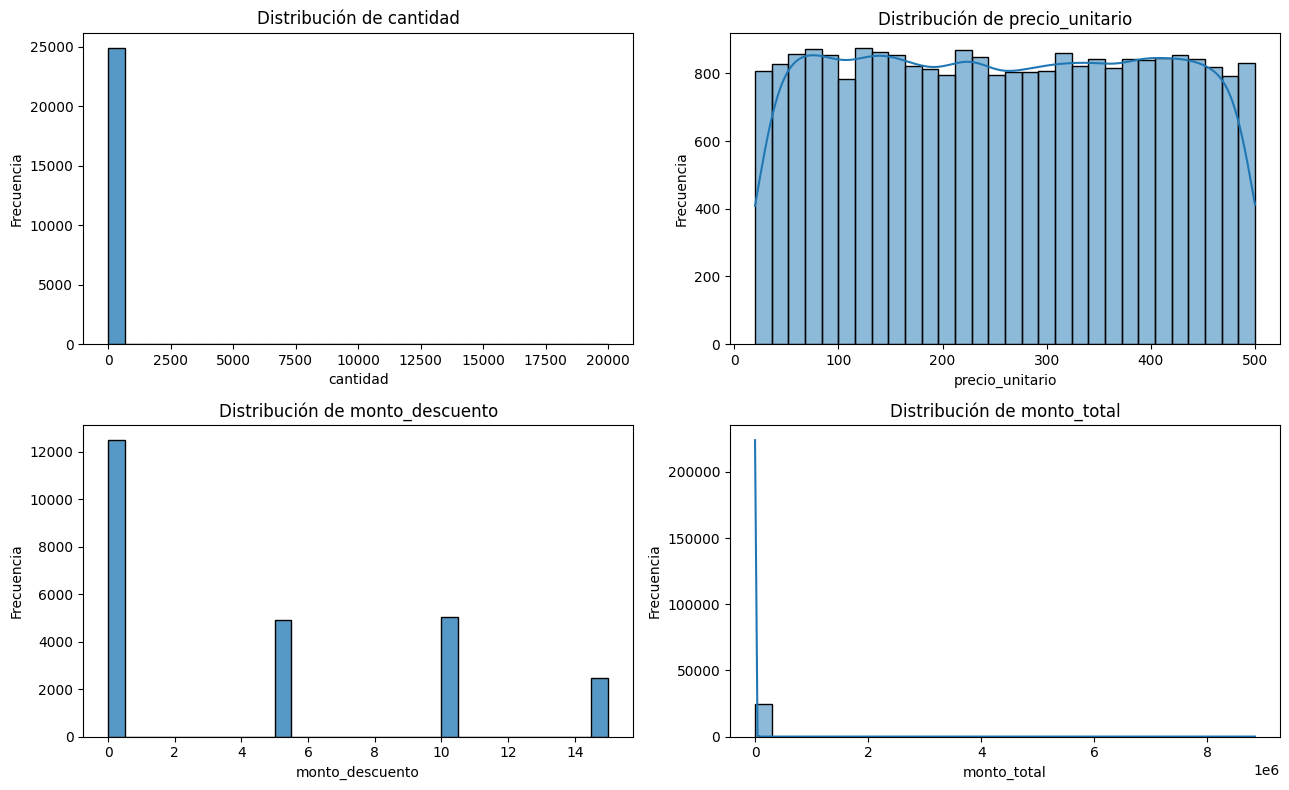

In [64]:
columnas_numericas = [
    "cantidad",
    "precio_unitario",
    "monto_descuento",
    "monto_total"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, columna in zip(axes.flatten(), columnas_numericas):

    # Convertir temporalmente a float64
    datos = orders_clean[columna].astype("float64").dropna()

    sns.histplot(
        x=datos,
        bins=30,
        kde=columna in ["precio_unitario", "monto_total"],
        ax=ax
    )

    ax.set_title(f"Distribución de {columna}")
    ax.set_xlabel(columna)
    ax.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [65]:
print(orders_clean[
    ["cantidad", "precio_unitario", "monto_descuento", "monto_total"]
].dtypes)

cantidad           float64
precio_unitario    float64
monto_descuento    float64
monto_total        float64
dtype: object


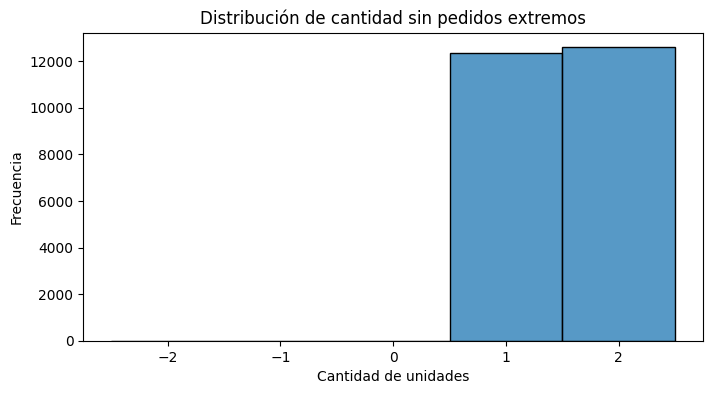

In [66]:
orders_sin_atipicos = orders_clean[
    ~orders_clean["cantidad"].isin([10000, 20000])
].copy()

plt.figure(figsize=(8, 4))

sns.histplot(
    data=orders_sin_atipicos,
    x="cantidad",
    discrete=True
)

plt.title("Distribución de cantidad sin pedidos extremos")
plt.xlabel("Cantidad de unidades")
plt.ylabel("Frecuencia")
plt.xticks([-2, -1, 0, 1, 2])
plt.show()

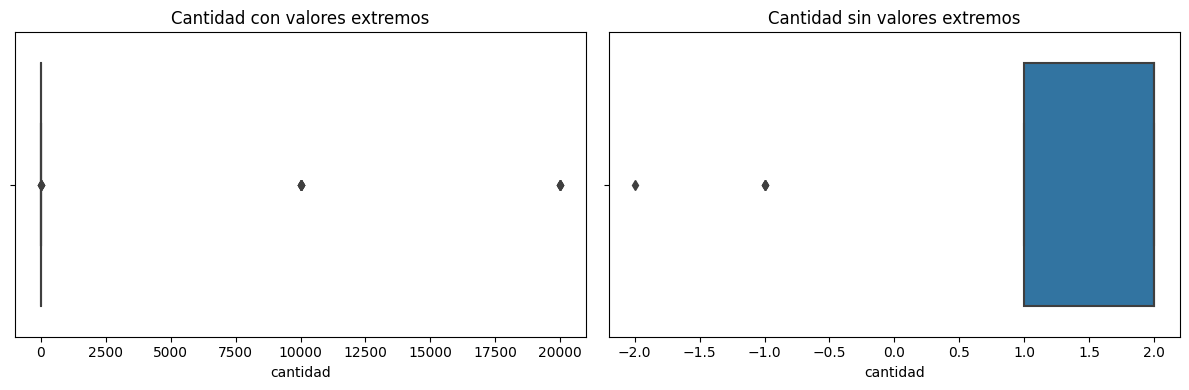

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(
    data=orders_clean,
    x="cantidad",
    ax=axes[0]
)
axes[0].set_title("Cantidad con valores extremos")

sns.boxplot(
    data=orders_sin_atipicos,
    x="cantidad",
    ax=axes[1]
)
axes[1].set_title("Cantidad sin valores extremos")

plt.tight_layout()
plt.show()

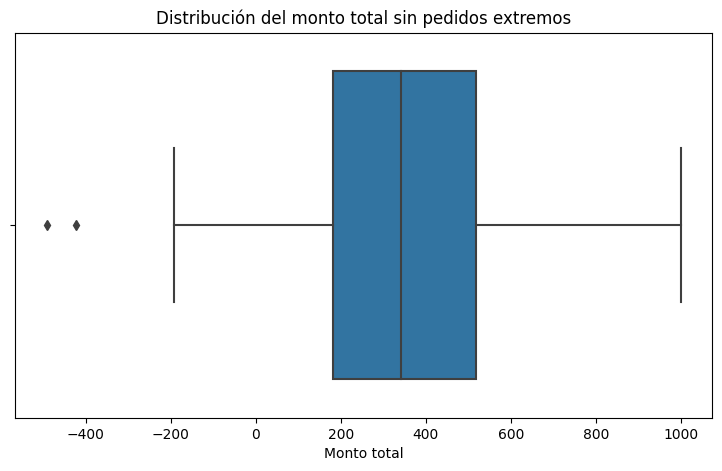

In [68]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=orders_sin_atipicos,
    x="monto_total"
)

plt.title("Distribución del monto total sin pedidos extremos")
plt.xlabel("Monto total")
plt.show()

De acuerdo con el análisis de los histogramas y diagramas de caja. Se idenfica visualmente la concentración de los pedidos de 1 y 2 unidades, se observan los valores atipicos, provocando una fuerte asimetría positivaen la distribución del monto total

Por otra parte, precio_unitario presenta una distribución aproximadamente uniforme, mientras que monto_descuento se concentra en valores discretos de 0, 5, 10 y 15.

También se identificaron cuatro registros con cantidades negativas, considerados posibles devoluciones, y cincuenta registros con cantidades desconocidas.

Se procedió a conservar los registros originales, clasificar las operaciones según sus características y realizar análisis diferenciados para evitar distorsiones en los indicadores comerciales.

In [69]:
orders_clean["cantidad"] = orders_clean["cantidad"].astype("Int64")

In [70]:
orders_clean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 25000 entries, 0 to 24999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25000 non-null  object        
 1   id_usuario          25000 non-null  object        
 2   fecha_hora_pedido   25000 non-null  datetime64[ns]
 3   pais                25000 non-null  object        
 4   dispositivo         25000 non-null  object        
 5   fuente_referencia   25000 non-null  object        
 6   nombre_producto     25000 non-null  object        
 7   categoria_producto  25000 non-null  object        
 8   cantidad            24950 non-null  Int64         
 9   precio_unitario     24950 non-null  float64       
 10  monto_descuento     24950 non-null  float64       
 11  monto_total         25000 non-null  float64       
 12  monto_esperado      24950 non-null  float64       
 13  diferencia_monto    24950 non-null  float64   

Antes de continuar se procede a cambiar el formato de cantidad a número entero. 

---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [71]:


# exportar datasets
orders_clean.to_csv('orders_clean.csv', index=False)
catalog_clean.to_csv('catalog_clean.csv', index=False)
marketing_clean.to_csv('marketing_clean.csv', index=False)



---

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)? 
- ¿Cuál es el costo total? 
- ¿Cuánto se ha invertido en marketing? 
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden? 
- ¿Cuál es la cantidad promedio de productos por orden? 
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal? 

In [72]:
# tu código aquí
orders_costos = orders_clean.merge(
    catalog_clean[
        ["nombre_producto", "costo_unitario"]
    ],
    on="nombre_producto",
    how="left",
    validate="many_to_one"
)

display(orders_costos.head())

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,monto_esperado,diferencia_monto,estado_monto,tipo_movimiento,estado_datos,tipo_cantidad,costo_unitario
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2,332.69,0.0,665.37,665.38,-0.01,Consistente,Venta u otro movimiento,Completo,Habitual,189.31
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electrónica,1,176.86,5.0,171.86,171.86,0.00,Consistente,Venta u otro movimiento,Completo,Habitual,25.21
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2,102.99,10.0,195.99,195.98,0.01,Inconsistente,Venta u otro movimiento,Completo,Habitual,176.64
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electrónica,1,257.87,15.0,242.87,242.87,0.00,Consistente,Venta u otro movimiento,Completo,Habitual,25.21
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1,336.28,0.0,336.28,336.28,0.00,Consistente,Venta u otro movimiento,Completo,Habitual,176.64


In [73]:
print("Pedidos originales:", len(orders_clean))
print("Pedidos después del merge:", len(orders_costos))

print(
    "Pedidos sin costo unitario:",
    orders_costos["costo_unitario"].isna().sum()
)

Pedidos originales: 25000
Pedidos después del merge: 25000
Pedidos sin costo unitario: 30


In [74]:
orders_costos["costo_total"] = (
    orders_costos["cantidad"]
    * orders_costos["costo_unitario"]
)

display(
    orders_costos[
        [
            "id_pedido",
            "nombre_producto",
            "cantidad",
            "costo_unitario",
            "costo_total"
        ]
    ].head()
)

,id_pedido,nombre_producto,cantidad,costo_unitario,costo_total
0,order_0,Jacket-Winter-M,2,189.31,378.62
1,order_1,Tablet-Standard-64GB,1,25.21,25.21
2,order_2,Blender-XL-Red,2,176.64,353.28
3,order_3,Tablet-Standard-64GB,1,25.21,25.21
4,order_4,Blender-XL-Red,1,176.64,176.64


Las cantidades negativas producirán costos negativos, lo cual puede representar una reversión del costo de venta si la mercancía fue devuelta al inventario. Como todavía no confirmamos esas operaciones, trataremos ese resultado como provisional.
También hay que recordar los 50 pedidos con cantidades desconocidas no tendrán un costo calculable, aunque sí tengan monto_total.

In [75]:
# Convertir temporalmente a float64
orders_costos["costo_total"] = (
    orders_costos["cantidad"].astype("float64")
    * orders_costos["costo_unitario"]
)

# Sumar costos conocidos
costo_productos = orders_costos["costo_total"].sum()

print(f"Costo de productos calculables: ${costo_productos:,.2f}")

Costo de productos calculables: $43,124,018.41


In [76]:

revenue = orders_costos["monto_total"].sum()

gasto_marketing = marketing_clean["gasto"].sum()

profit = revenue - costo_productos - gasto_marketing

margen_profit = profit / revenue * 100

print(f"Ingresos totales: ${revenue:,.2f}")
print(f"Costos calculables: ${costo_productos:,.2f}")
print(f"Inversión en marketing: ${gasto_marketing:,.2f}")
print(f"Profit estimado: ${profit:,.2f}")
print(f"Margen estimado: {margen_profit:.2f}%")


Ingresos totales: $51,987,462.26
Costos calculables: $43,124,018.41
Inversión en marketing: $2,871,843.53
Profit estimado: $5,991,600.32
Margen estimado: 11.53%


Se calcula los KPI´S sin descartar los diez pedidos extraordinarios que representan el 81.45% de los ingresos y 80 no identificados o no recalculables, con el cual se obtiene una ganancia estimada  $5,991,600.32 lo que representa un margen de ganancia de 11.53%, sin embargo se procede a realizar el calculo sin los 10 valores extraordinarios a continuación.

In [77]:
# Identificar los 10 pedidos extraordinarios
atipicos = orders_costos[
    orders_costos["cantidad"].isin([10000, 20000])
]

# Calcular ingresos y costos extraordinarios
ingresos_atipicos = atipicos["monto_total"].sum()
costos_atipicos = atipicos["costo_total"].sum()

# Rentabilidad sin pedidos extraordinarios
ingresos_sin_atipicos = revenue - ingresos_atipicos
costos_sin_atipicos = costo_productos - costos_atipicos

profit_sin_atipicos = (
    ingresos_sin_atipicos
    - costos_sin_atipicos
    - gasto_marketing
)

margen_sin_atipicos = (
    profit_sin_atipicos / ingresos_sin_atipicos * 100
)

print(f"Ingresos sin atípicos: ${ingresos_sin_atipicos:,.2f}")
print(f"Costos sin atípicos: ${costos_sin_atipicos:,.2f}")
print(f"Profit sin atípicos: ${profit_sin_atipicos:,.2f}")
print(f"Margen sin atípicos: {margen_sin_atipicos:.2f}%")

Ingresos sin atípicos: $9,642,762.26
Costos sin atípicos: $3,828,818.41
Profit sin atípicos: $2,942,100.32
Margen sin atípicos: 30.51%


Al excluir temporalmente diez pedidos extraordinarios, los ingresos disminuyeron a $9,642,762.26, mientras que el beneficio estimado se sitúo en $2,942,100.32, con un margen del 30.51%. Estos resultados indican que las operaciones extraordinarias incrementan significativamente los ingresos y el beneficio absoluto, pero presentan una rentabilidad porcentual inferior a la del resto de las operaciones.
Se recomienda validar dichas transacciones y analizar sus costos para determinar su impacto comercial real. Aunque en los 2 escenarios la empresa presenta rentabilidad de negocio. 

In [79]:
ticket_promedio = (
    orders_clean["monto_total"].sum()
    / orders_clean["id_pedido"].nunique()
)

print(f"Ticket promedio: ${ticket_promedio:,.2f}")

Ticket promedio: $2,079.50


In [80]:
orders_sin_atipicos = orders_clean[
    ~orders_clean["cantidad"].isin([10000, 20000])
].copy()

In [81]:
ticket_sin_atipicos = (
    orders_sin_atipicos["monto_total"].sum()
    / orders_sin_atipicos["id_pedido"].nunique()
)

print(f"Ticket promedio sin atípicos: ${ticket_sin_atipicos:,.2f}")

Ticket promedio sin atípicos: $385.86


In [82]:
ticket_general = orders_clean["monto_total"].mean()

print(f"Ticket promedio general: ${ticket_general:,.2f}")
print(f"Ticket promedio sin atípicos: ${ticket_sin_atipicos:,.2f}")

Ticket promedio general: $2,079.50
Ticket promedio sin atípicos: $385.86


Al excluir temporalmente los diez pedidos extraordinarios, el ticket promedio disminuye considerablemente, pasando de $2,079.50 a $385.86. Esto demuestra que las transacciones atípicas distorsionan el promedio general de ventas.

In [83]:
# sin excluir los diez pedidos extraordinarios
cantidad_promedio_general = orders_clean["cantidad"].mean()

print(
    f"Cantidad promedio general: "
    f"{cantidad_promedio_general:.2f}"
)

Cantidad promedio general: 7.12


In [84]:
# Excluyendo valores extraordinarios, negativos o desconocidos.
pedidos_habituales = orders_clean[
    orders_clean["cantidad"].isin([1, 2])
].copy()

cantidad_promedio_habitual = (
    pedidos_habituales["cantidad"].mean()
)

print(
    f"Cantidad promedio habitual: "
    f"{cantidad_promedio_habitual:.2f} unidades"
)

Cantidad promedio habitual: 1.50 unidades


Con las frecuencias que ya identificaron, el promedio habitual es aproximadamente 1.50 unidades por pedido, considerando solo los pedidos habituales entre 1 y 2 productos. 

In [85]:
producto_mas_vendido = (
    pedidos_habituales
    .groupby("nombre_producto")["cantidad"]
    .sum()
    .sort_values(ascending=False)
)

display(producto_mas_vendido)

nombre_producto
Vacuum-Pro-Black        6284
Blender-XL-Red          6279
Jacket-Winter-M         6256
Sneakers-Urban-42       6172
Laptop-Gaming-16GB      4198
Tablet-Standard-64GB    4153
Phone-Pro-128GB         4140
No identificado           45
Name: cantidad, dtype: Int64

Vacuum-Pro-Black es el producto que acumula mayor cantidad de unidades vendidas con 6,284 unidades

In [86]:
marketing_por_canal = (
    marketing_clean
    .groupby("canal", dropna=False)["gasto"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

marketing_por_canal.columns = [
    "canal",
    "gasto_total"
]

marketing_por_canal["participacion_pct"] = (
    marketing_por_canal["gasto_total"]
    / marketing_por_canal["gasto_total"].sum()
    * 100
)

display(marketing_por_canal.round(2))

,canal,gasto_total,participacion_pct
0,social,976818.37,34.01
1,organic,972650.96,33.87
2,paid_search,922374.20,32.12


El canal Social concentra la mayor proporción del gasto en marketing, con un 34.01% del presupuesto total. Sin embargo, los demás canales presentan porcentajes similares, lo que indica una distribución relativamente uniforme de la inversión entre los tres canales.

---

## 🔹
 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?

---

In [87]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [88]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [89]:

# =========================
query_events = '''
SELECT distinct nombre_evento
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,nombre_evento
0,add_payment_info
1,first_visit
2,begin_checkout
3,add_to_cart
4,select_item


In [90]:

# =========================
query_events = '''
SELECT id_usuario, timestamp_evento, nombre_evento
FROM events
WHERE id_usuario = 'user_5883'
ORDER BY id_usuario, timestamp_evento Desc
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,timestamp_evento,nombre_evento
0,user_5883,2025-06-17,select_item
1,user_5883,2025-06-17,add_payment_info
2,user_5883,2025-06-11,add_to_cart
3,user_5883,2025-06-10,select_item
4,user_5883,2025-06-01,first_visit


Se analiza los diferentes eventos que hay antes de llegar a la compra y se ordenan.

In [91]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''
SELECT
    nombre_evento,
    COUNT(DISTINCT id_usuario)
FROM events
WHERE nombre_evento IN ('first_visit','select_item','add_to_cart','begin_checkout','add_payment_info','purchase')
GROUP BY nombre_evento
ORDER BY CASE nombre_evento
    WHEN 'first_visit' THEN 1
    WHEN 'select_item' THEN 2
    WHEN 'add_to_cart' THEN 3
    WHEN 'begin_checkout' THEN 4
    WHEN 'add_payment_info' THEN 5
    WHEN 'purchase' THEN 6
END;
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,count
0,first_visit,7796
1,select_item,7582
2,add_to_cart,7634
3,begin_checkout,7208
4,add_payment_info,6250
5,purchase,6240


Se genera los conteos de usuarios unicos por evento

In [92]:
# PARTE 2: Conversiones
# ======================

query_conversion = '''

WITH cte_first AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'first_visit'
),
cte_select AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'select_item'
),
cte_add AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_to_cart'
),
cte_checkout AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'begin_checkout'
),
cte_addpayment AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_payment_info'
),
cte_purchase AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'purchase'
),
totales AS (
    SELECT
        (SELECT COUNT(*) FROM cte_first) AS first_users,
        (SELECT COUNT(*) FROM cte_select) AS select_users,
        (SELECT COUNT(*) FROM cte_add) AS add_users,
        (SELECT COUNT(*) FROM cte_checkout) AS checkout_users,
        (SELECT COUNT(*) FROM cte_addpayment) AS payment_users,
        (SELECT COUNT(*) FROM cte_purchase) AS purchase_users
)
SELECT
    *,
    ROUND(
        (first_users - select_users) * 100.0
        / NULLIF(first_users, 0), 2
    ) AS dropoff_after_first_visit,

    ROUND(
        (select_users - add_users) * 100.0
        / NULLIF(select_users, 0), 2
    ) AS dropoff_after_select_item,

    ROUND(
        (add_users - checkout_users) * 100.0
        / NULLIF(add_users, 0), 2
    ) AS dropoff_after_add_to_cart,

    ROUND(
        (checkout_users - payment_users) * 100.0
        / NULLIF(checkout_users, 0), 2
    ) AS dropoff_after_begin_checkout,

    ROUND(
        (payment_users - purchase_users) * 100.0
        / NULLIF(payment_users, 0), 2
    ) AS dropoff_after_add_payment_info

    
FROM totales
'''


conversion = pd.read_sql(query_conversion, con=engine)
conversion



,first_users,select_users,add_users,checkout_users,payment_users,purchase_users,dropoff_after_first_visit,dropoff_after_select_item,dropoff_after_add_to_cart,dropoff_after_begin_checkout,dropoff_after_add_payment_info
0,7796,7582,7634,7208,6250,6240,2.74,-0.69,5.58,13.29,0.16


El funnel muestra que la mayor disminución porcentual de usuarios se presenta entre begin_checkout y add_payment_info, con una reducción del 13.29%, tambien se muestra un -0.69% lo cual representa el aumento de usuarios que hubo entre select_item y add_to_cart, es posible cuando contamos usuarios por evento de forma independiente y confirma que debemos distinguir este análisis descriptivo de un funnel secuencial.

---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 
Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users` 
- `user_activity` 

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`


In [93]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''

users = pd.read_sql(query_users, con=engine)
users.head(3)


,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [94]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


---

In [95]:

# Retención por cohortes
# ======================

query_cohort_retention_final = '''
WITH cohortes AS (
    SELECT
        id_usuario,
        DATE_TRUNC(
            'month',
            CAST(fecha_registro AS DATE)
        )::DATE AS cohorte
    FROM users
),

retencion AS (
    SELECT
        c.cohorte,
        COUNT(DISTINCT c.id_usuario) AS usuarios_iniciales,

        COUNT(DISTINCT CASE
            WHEN a.dias_despues_registro BETWEEN 7 AND 13
                 AND a.activo = 1
            THEN c.id_usuario
        END) AS retenido_w1,

        COUNT(DISTINCT CASE
            WHEN a.dias_despues_registro BETWEEN 14 AND 20
                 AND a.activo = 1
            THEN c.id_usuario
        END) AS retenido_w2,

        COUNT(DISTINCT CASE
            WHEN a.dias_despues_registro BETWEEN 21 AND 27
                 AND a.activo = 1
            THEN c.id_usuario
        END) AS retenido_w3

    FROM cohortes c
    LEFT JOIN user_activity a
        ON c.id_usuario = a.id_usuario
    GROUP BY c.cohorte
)

SELECT
    cohorte,
    usuarios_iniciales,
    retenido_w1,
    retenido_w2,
    retenido_w3,

    ROUND(
        retenido_w1 * 100.0 /
        NULLIF(usuarios_iniciales, 0), 2
    ) AS semana_1,

    ROUND(
        retenido_w2 * 100.0 /
        NULLIF(usuarios_iniciales, 0), 2
    ) AS semana_2,

    ROUND(
        retenido_w3 * 100.0 /
        NULLIF(usuarios_iniciales, 0), 2
    ) AS semana_3

FROM retencion
ORDER BY cohorte;
'''

# Ejecutar la consulta

cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final




,cohorte,usuarios_iniciales,retenido_w1,retenido_w2,retenido_w3,semana_1,semana_2,semana_3
0,2025-01-01,1627,697,668,656,42.84,41.06,40.32
1,2025-02-01,1444,611,609,635,42.31,42.17,43.98
2,2025-03-01,1636,677,705,690,41.38,43.09,42.18
3,2025-04-01,1606,680,697,663,42.34,43.40,41.28
4,2025-05-01,1687,695,676,706,41.20,40.07,41.85


El análisis de cohortes muestra que, durante enero de 2025, la retención de usuarios fue del 42.84% en la primera semana, disminuyendo progresivamente hasta alcanzar el 40.32% en la tercera semana, lo que representa una reducción de 2.52 puntos porcentuales.

Por otra parte, la cohorte de febrero inició con una retención del 42.31% y presentó un incremento hasta alcanzar el 43.98% en la tercera semana, posicionándose como la cohorte con mayor retención al finalizar el periodo analizado.

En general, las cohortes presentan porcentajes de retención relativamente estables, que oscilan entre el 40% y el 44%, sin observarse disminuciones pronunciadas a nivel global.

Estos resultados sugieren que existe un comportamiento de actividad relativamente constante entre las cohortes, aunque también se identifican oportunidades para implementar estrategias de fidelización y reactivación de usuarios.

##
 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado** 
4. **Interpretar el resultado**
  

---
Hipótesis estadística
   - **H₀ (Hipótesis nula):** ... La tasa de conversión de compra es igual en ambas variantes (control y tratamiento). Las diferencias observadas pueden atribuirse a la variabilidad aleatoria del muestreo.
   - **H₁ (Hipótesis alternativa):** ... La tasa de conversión de compra es diferente entre ambas variantes (control y tratamiento), lo que indicaría un posible impacto de la modificación de la interfaz del checkout sobre la conversión.
   
**Test estadístico:** ... Prueba z 
**Nivel de significancia alpha:** ... 0.05

In [96]:
from statsmodels.stats.proportion import proportions_ztest

In [97]:
# tu código aquí
checkout = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')



In [98]:
checkout.head(10)

,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12
5,exp_user_5,control,0,mobile,Mexico,206.70,2025-01-26
6,exp_user_6,control,0,desktop,Mexico,280.11,2025-04-15
7,exp_user_7,tratamiento,0,mobile,Argentina,28.47,2025-03-18
8,exp_user_8,tratamiento,0,desktop,Mexico,287.04,2025-02-05
9,exp_user_9,control,0,mobile,Argentina,258.91,2025-02-11


In [99]:
checkout.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  object 
 1   variante         10000 non-null  object 
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  object 
 4   pais             10000 non-null  object 
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 547.0+ KB


In [100]:
# Validar usuarios y conversiones
print("Usuarios duplicados:", checkout["id_usuario"].duplicated().sum())
print("Valores de conversión:", checkout["convirtio"].unique())

Usuarios duplicados: 0
Valores de conversión: [0 1]


In [101]:
# Contar número de exitos y número total de registros
conversiones = checkout.groupby('variante')['convirtio'].sum()
totales = checkout.groupby('variante')['convirtio'].count()

# Pasar los valores a formato lista
exitos = [conversiones['control'], conversiones['tratamiento']]
observaciones = [totales['control'], totales['tratamiento']]

# Aplicar prueba y visualizar resultados
z_stat, p_value = proportions_ztest(exitos , observaciones)
print(f"Estadístico z: {z_stat}")
print(f"Valor p: {p_value}")

# Interpretar resultados
alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")

Estadístico z: -0.8132782986429474
Valor p: 0.41605851639119995
No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.


In [102]:
# Obtener tasa o porcentaje de éxito
tasa_control = exitos[0] / observaciones[0]
tasa_tratamiento = exitos[1] / observaciones[1]

print(f"Tasa de conversión variante control: {tasa_control:.2%}")
print(f"Tasa de conversión variante tratamiento: {tasa_tratamiento:.2%}")

# Interpretar dirección de resultados
if tasa_control > tasa_tratamiento:
    print(f"\nLa variante control tiene una mayor tasa de conversión ({tasa_control - tasa_tratamiento:.2%}).")
elif tasa_tratamiento > tasa_control:
    print(f"\nLa variante tratamiento tiene una mayor tasa de conversión ({tasa_tratamiento - tasa_control:.2%})")
else:
    print("\nAmbas variantes tienen la misma tasa de conversión.")

Tasa de conversión variante control: 15.69%
Tasa de conversión variante tratamiento: 16.29%

La variante tratamiento tiene una mayor tasa de conversión (0.60%)


Se realizó un experimento A/B para evaluar el impacto de una modificación en la interfaz del checkout sobre la tasa de conversión de compra.

Los resultados muestran que la variante control obtuvo una tasa de conversión del 15.69%, mientras que la variante tratamiento alcanzó el 16.29%, representando una mejora observada de 0.60 puntos porcentuales a favor del tratamiento.

Sin embargo, al aplicar la prueba Z de dos proporciones, se obtuvo un estadístico Z de -0.8133 y un valor p de 0.4161.

Dado que el valor p es mayor que el nivel de significancia establecido (α = 0.05), no se rechaza la hipótesis nula.

Conclusión: Aunque la variante tratamiento presenta una tasa de conversión ligeramente superior, la diferencia no es estadísticamente significativa. Por lo tanto, no existe evidencia suficiente para concluir que la modificación de la interfaz haya generado una mejora real en las conversiones.

Recomendaciones de negocio

-Mantener la interfaz actual como referencia mientras se evalúan nuevas mejoras.
-Analizar la conversión por dispositivo y país para identificar posibles oportunidades de optimización.
-Revisar elementos del checkout que puedan generar fricción, como formularios, métodos de pago y navegación.
-Realizar nuevos experimentos A/B con un tamaño de muestra adecuado para detectar mejoras pequeñas.

Se recomienda no implementar la nueva interfaz únicamente con base en la diferencia observada, ya que el experimento no demuestra un beneficio estadísticamente significativo.

---

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión. 

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

---

## 🚀 Entrega Final

Comparte el acceso a tu Dashboard para revisión.   
Puedes entregar el Dashboard utilizando **Power BI o Tableau**.

Incluye **uno de los siguientes**:

- 🔗 Link público del dashboard publicado en **Power BI Service o Tableau Public / Tableau Cloud**
- 🔗 Link de **Google Drive o OneDrive** con el archivo del proyecto (`.pbix`) y los 3 csvs limpios.


### 📎 Enlace del Dashboard

In [ ]:
# (Pega aquí tu link)
# link de power bi o tableau
# link de one drive / google drive